# Image processing: scaling, camera noise and centering

Simulations deliver smooth, noise-free fields in arbitrary units, centred
wherever the optics put them. Measured images look different: they are
photon counts with noise, quantized by an ADC, and spots wander around from
frame to frame. `pyoptics.processing` provides small processors that bridge
this gap:

| Processor | What it does |
|---|---|
| `Scaler` | scales a field or intensity to a given peak, mean or total value of the field strength $\lvert E\rvert$ or the intensity $I = \lvert E\rvert^2$ |
| `CameraNoiser` | adds noise: Gaussian, Poisson photon noise, or a full linear camera model (EMVA 1288) |
| `Shifter` | shifts images by (subpixel) distances with the Fourier shift theorem |
| `Centerer` | shifts images so that their intensity centroid lies at a given point |

Every processor is a callable that takes a single image (2d array) or an image
stack (3d array, last index numbering the images). The helpers
`utils.center_of_mass()` and `utils.add_camera_noise()` are also used below.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$. In this module
the intensity of a field is simply $\lvert E\rvert^2$ (without the factor
$n/(2Z_0)$ of `utils.I()`); after scaling it is interpreted as the expected
number of photons per pixel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

from pyoptics import imaging
from pyoptics.processing import Scaler, CameraNoiser, Shifter, Centerer
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics.utils import grid2d, center_of_mass, add_camera_noise

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl, NA = 0.5, 0.25          # µm
k = 2*np.pi/wl
L, N = 32.0, 128            # 0.25 µm pixels, 0.61 λ/NA = 1.22 µm Airy radius
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
dx = x[1] - x[0]
ext = (x[0], x[-1], y[0], y[-1])

h = imaging.get_psf(x, y, NA, k)   # amplitude PSF in focus (complex field)

def defocus(U, z):
    # propagate by z; for z < 0 by time reversal (see notebook 15)
    if z >= 0:
        return rayleigh_sommerfeld_I_TF(U, x, y, z, wl)[0]
    return np.conj(rayleigh_sommerfeld_I_TF(np.conj(U), x, y, -z, wl)[0])

z_stack = np.linspace(-16, 16, 9)   # ±2 λ/NA², i.e. ±2 depths of focus
focus_stack = np.dstack([defocus(h, z) for z in z_stack])
print("stack shape:", focus_stack.shape, focus_stack.dtype)

stack shape: (128, 128, 9) complex128


## 1. Scaling with `Scaler`

### Field strength or intensity?

`Scaler(value, measure, quantity)` multiplies an image by a real factor such
that the chosen `measure` (`"peak"`, `"mean"` or `"total"`) of the chosen
`quantity` (`"intensity"` or `"field"`) equals `value`. Whether the input is a
field or an intensity is decided by `image_type` (default `"auto"`: complex
arrays are fields, real arrays intensities). A field is multiplied by $c$ when
the intensity is multiplied by $c^2$, so all combinations are consistent:
scaling the field strength to a peak of 3 is the same as scaling the
intensity to a peak of 9. The phase of a field is never touched.

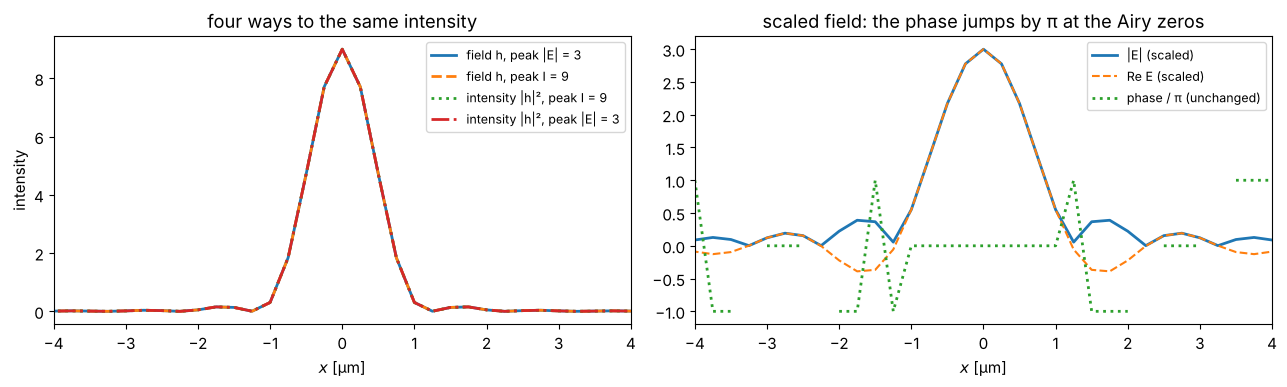

In [2]:
I_psf = np.abs(h)**2
cases = [
    ("field h, peak |E| = 3", Scaler(3.0, quantity="field")(h)),
    ("field h, peak I = 9", Scaler(9.0)(h)),
    ("intensity |h|², peak I = 9", Scaler(9.0)(I_psf)),
    ("intensity |h|², peak |E| = 3", Scaler(3.0, quantity="field")(I_psf)),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (label, img), ls in zip(cases, ("-", "--", ":", "-.")):
    I_img = np.abs(img)**2 if np.iscomplexobj(img) else img
    axes[0].plot(x, I_img[N//2], ls, lw=2, label=label)
axes[0].set_xlim(-4, 4); axes[0].set_xlabel("$x$ [µm]"); axes[0].set_ylabel("intensity")
axes[0].legend(fontsize=9); axes[0].set_title("four ways to the same intensity")

scaled = Scaler(3.0, quantity="field")(h)
axes[1].plot(x, np.abs(scaled[N//2]), lw=2, label="|E| (scaled)")
axes[1].plot(x, np.real(scaled[N//2]), "--", label="Re E (scaled)")
phase = np.where(np.abs(scaled[N//2]) > 0.05, np.angle(scaled[N//2]), np.nan)
axes[1].plot(x, phase/np.pi, ":", lw=2, label="phase / π (unchanged)")
axes[1].set_xlim(-4, 4); axes[1].set_xlabel("$x$ [µm]"); axes[1].legend(fontsize=9)
axes[1].set_title("scaled field: the phase jumps by π at the Airy zeros")
fig.tight_layout()

### Peak, mean and total

For `measure="total"`, the intensity measure is the power $P = \sum I\,\Delta A$
(pass the pixel area as `pixel_area`), the field measure the norm
$\sqrt{\sum \lvert E\rvert^2\,\Delta A} = \sqrt{P}$. Scaling to a fixed power
is the natural normalization for a beam; a fixed peak is what one wants for
display or to set the brightest pixel of a camera image.

The through-focus stack shows the difference. Free-space propagation
conserves power, but the peak intensity drops as the spot grows. Scaling every
image to the same peak hides this; scaling to the same power keeps it.

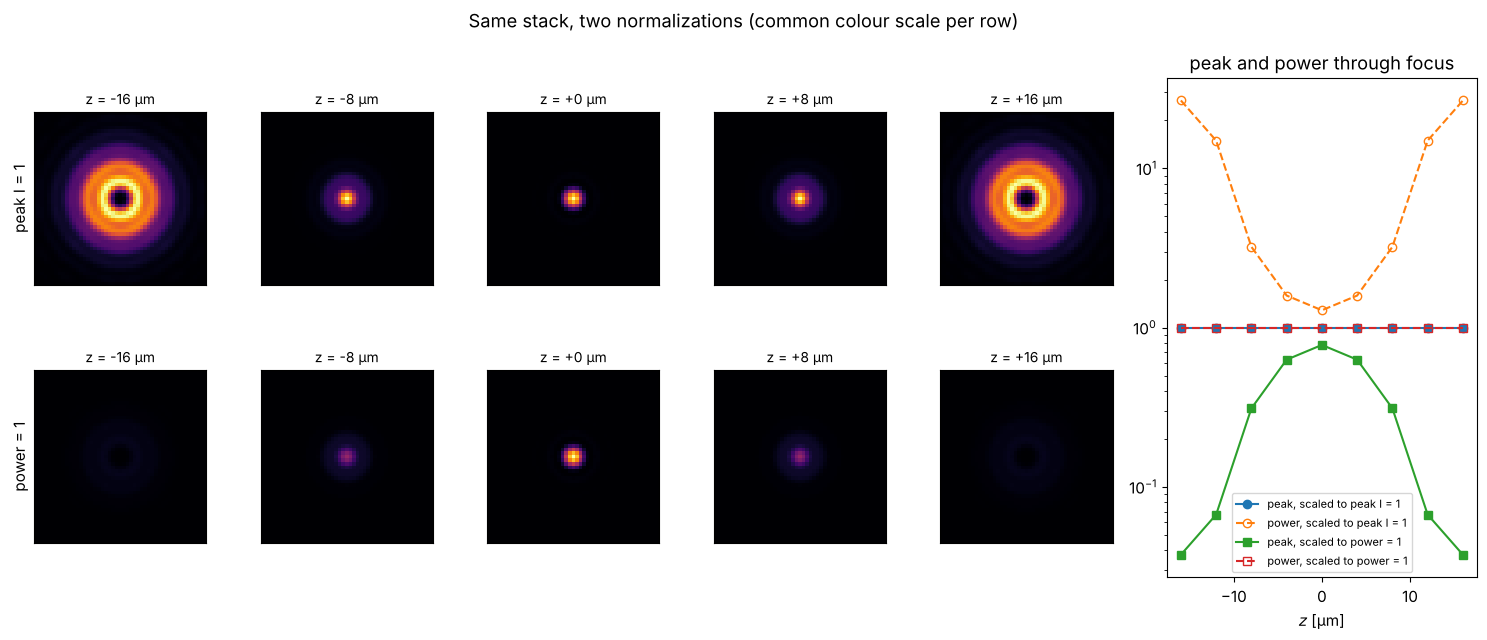

In [3]:
dA = dx**2
by_peak = Scaler(1.0)(focus_stack)
by_power = Scaler(1.0, measure="total", pixel_area=dA)(focus_stack)

fig = plt.figure(figsize=(15, 6.5))
gs = fig.add_gridspec(2, 6, width_ratios=[1, 1, 1, 1, 1, 1.8])
for row, (stack, title) in enumerate(((by_peak, "peak I = 1"), (by_power, "power = 1"))):
    I_st = np.abs(stack)**2
    vmax = I_st.max()
    for col, i in enumerate((0, 2, 4, 6, 8)):
        ax = fig.add_subplot(gs[row, col])
        ax.imshow(I_st[:, :, i], extent=ext, cmap="inferno", vmin=0, vmax=vmax)
        ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"z = {z_stack[i]:+.0f} µm", fontsize=10)
        if col == 0:
            ax.set_ylabel(title)
ax = fig.add_subplot(gs[:, 5])
for stack, label, m in ((by_peak, "scaled to peak I = 1", "o-"), (by_power, "scaled to power = 1", "s-")):
    I_st = np.abs(stack)**2
    ax.plot(z_stack, I_st.max(axis=(0, 1)), m, label=f"peak, {label}")
    ax.plot(z_stack, I_st.sum(axis=(0, 1))*dA, m.replace("-", "--"), mfc="none",
            label=f"power, {label}")
ax.set_xlabel("$z$ [µm]"); ax.set_yscale("log"); ax.legend(fontsize=8)
ax.set_title("peak and power through focus")
fig.suptitle("Same stack, two normalizations (common colour scale per row)")
fig.tight_layout()

### One factor for the whole stack: `per_image=False`

By default every image of a stack is scaled individually. With
`per_image=False`, one common factor is computed from the whole stack (global
peak, global mean, or the power averaged over the images). Relative
intensities between the images then survive, which is what one wants before
converting a simulated stack into photon numbers: the brightest pixel of the
whole stack gets the requested value, and defocused images are correspondingly
darker.

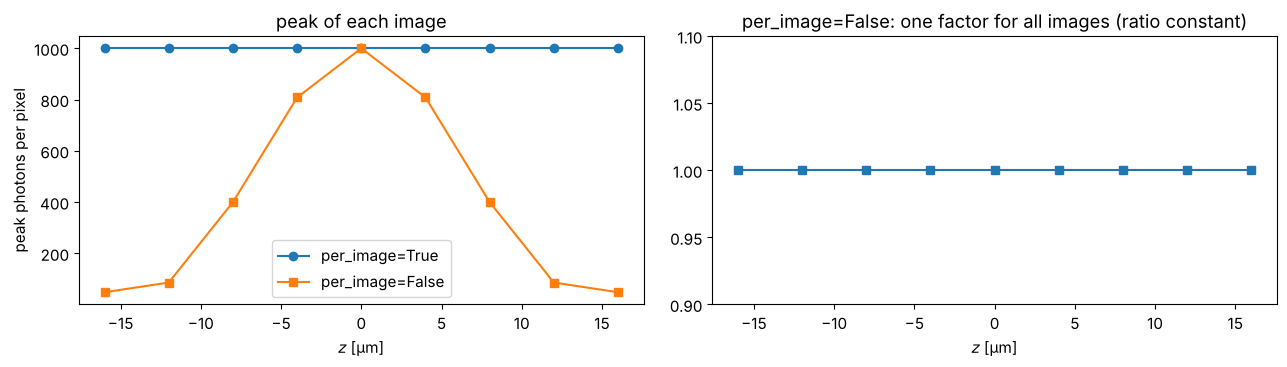

In [4]:
common = Scaler(1000.0, per_image=False)(focus_stack)   # 1000 photons in the brightest pixel
individual = Scaler(1000.0)(focus_stack)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(z_stack, np.abs(individual).max(axis=(0, 1))**2, "o-", label="per_image=True")
axes[0].plot(z_stack, np.abs(common).max(axis=(0, 1))**2, "s-", label="per_image=False")
axes[0].set_xlabel("$z$ [µm]"); axes[0].set_ylabel("peak photons per pixel"); axes[0].legend()
axes[0].set_title("peak of each image")
ratio = (np.abs(common)**2).sum(axis=(0, 1))/(np.abs(focus_stack)**2).sum(axis=(0, 1))
axes[1].plot(z_stack, ratio/ratio[0], "s-")
axes[1].set_ylim(0.9, 1.1); axes[1].set_xlabel("$z$ [µm]")
axes[1].set_title("per_image=False: one factor for all images (ratio constant)")
fig.tight_layout()

## 2. Camera noise with `CameraNoiser`

`CameraNoiser(model, ...)` offers three models:

* `"gaussian"`: additive white noise of standard deviation `sigma` (absolute,
  or relative to the peak with `relative=True`). It works on intensities and
  on complex fields (independent noise in real and imaginary part) and is the
  usual quick model for "some noise".
* `"poisson"`: pure photon shot noise. The input is the expected number of
  photons $\bar n$ per pixel, the output a Poisson distributed count with
  variance $\bar n$.
* `"camera"` (default): the linear camera model of the EMVA 1288 standard.
  Photons are converted to electrons with the quantum efficiency $\eta$
  (Poisson), dark electrons $\mu_d = $ `dark_current` $\times$ `exposure_time`
  are added (Poisson), the result is clipped at the full well capacity,
  multiplied by the pixel's gain deviation (PRNU), the read noise
  $\sigma_r$ (Gaussian) and the pixel's offset deviation (DSNU) are added,
  and finally the system gain $K$ (DN per electron), the offset and the ADC
  (rounding, clipping to $[0, 2^b - 1]$) are applied. Mean and temporal noise
  in digital numbers (DN) are

$$\mu_y = K(\eta\,\bar n + \mu_d) + \text{offset},\qquad
  \sigma_y = K\sqrt{\eta\,\bar n + \mu_d + \sigma_r^2}.$$

Fields are converted to $\lvert E\rvert^2$ for the photon-based models, so the
natural pipeline is `Scaler` (to photons) followed by `CameraNoiser`. All
noisers take `rng` (a seed or a `numpy.random.Generator`) for reproducible
noise.

### Shot noise at different light levels

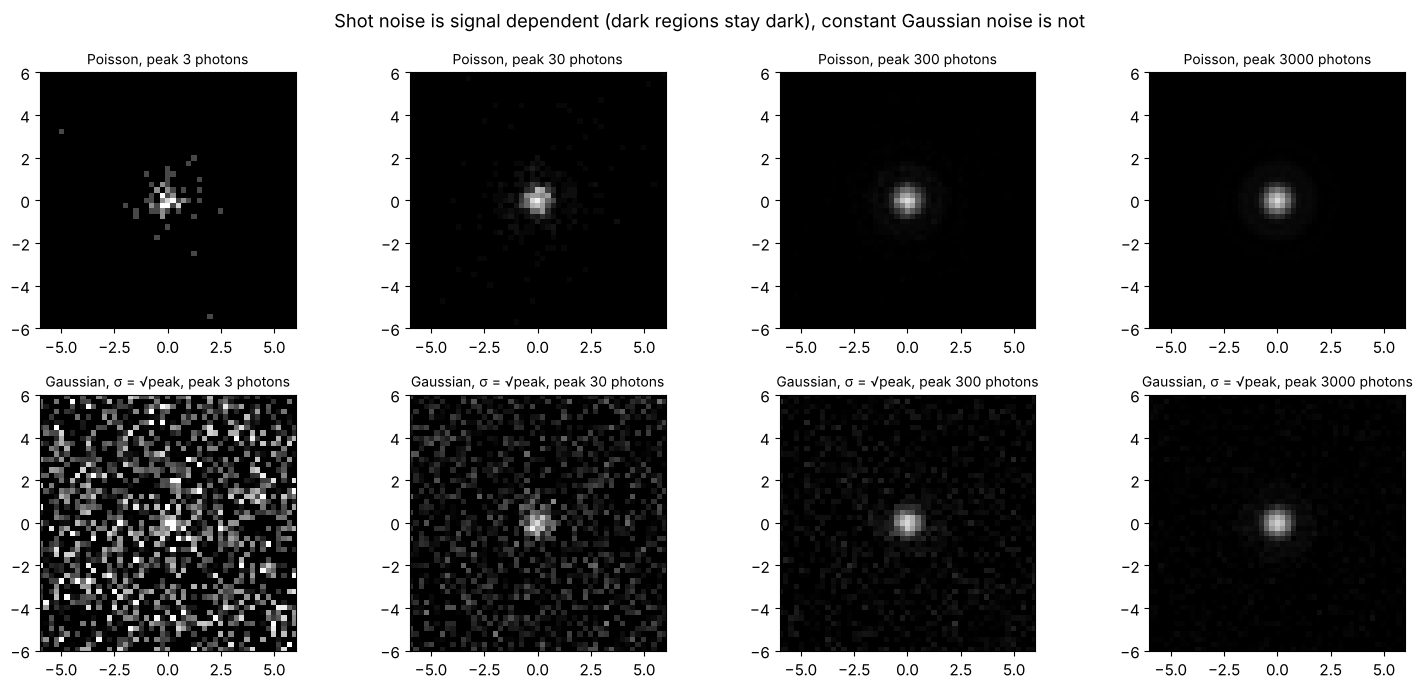

In [5]:
spot = np.abs(defocus(h, 4.0))**2
levels = (3, 30, 300, 3000)
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for col, n_peak in enumerate(levels):
    photons = Scaler(n_peak)(spot)
    shot = CameraNoiser("poisson", rng=col)(photons)
    gauss = CameraNoiser("gaussian", sigma=np.sqrt(n_peak), rng=col)(photons)
    for row, (img, name) in enumerate(((shot, "Poisson"), (gauss, "Gaussian, σ = √peak"))):
        axes[row, col].imshow(img, extent=ext, cmap="gray", vmin=0, vmax=1.2*n_peak)
        axes[row, col].set_xlim(-6, 6); axes[row, col].set_ylim(-6, 6)
        axes[row, col].set_title(f"{name}, peak {n_peak} photons", fontsize=10)
fig.suptitle("Shot noise is signal dependent (dark regions stay dark), constant Gaussian noise is not")
fig.tight_layout()

The Poisson images have a relative noise $1/\sqrt{\bar n}$ that is largest
in the dark regions but never produces negative counts. Gaussian noise of
constant $\sigma$ is equally strong everywhere and gives negative values in
the dark background. At low photon numbers the two distributions also differ
in shape: Poisson counts are discrete and skewed.

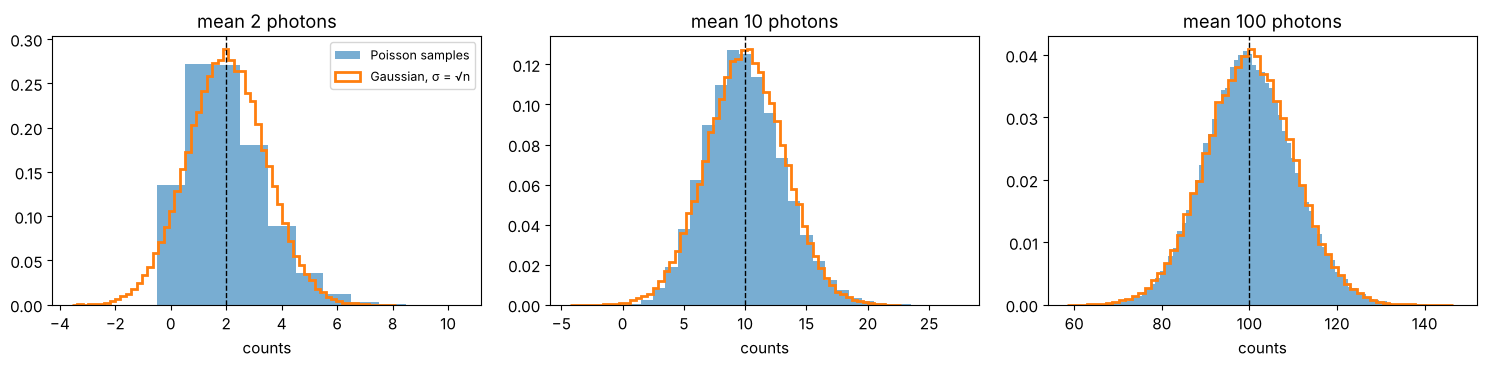

In [6]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, n in zip(axes, (2.0, 10.0, 100.0)):
    counts = CameraNoiser("poisson", rng=rng)(np.full((300, 300), n)).ravel()
    bins = np.arange(counts.min() - 0.5, counts.max() + 1.5)
    ax.hist(counts, bins=bins, density=True, alpha=0.6, label="Poisson samples")
    gauss = CameraNoiser("gaussian", sigma=np.sqrt(n), rng=rng)(np.full((300, 300), n)).ravel()
    ax.hist(gauss, bins=60, density=True, histtype="step", lw=2, label="Gaussian, σ = √n")
    ax.axvline(n, color="k", ls="--", lw=1)
    ax.set_title(f"mean {n:g} photons"); ax.set_xlabel("counts")
axes[0].legend(fontsize=9)
fig.tight_layout()

### Photon transfer curve and signal-to-noise ratio

The standard way to characterize a camera is the photon transfer curve:
illuminate it homogeneously at different levels and plot the temporal
variance against the mean signal. For the linear model this is a straight line
$\sigma_y^2 = K(\mu_y - \mu_{y,\text{dark}}) + \sigma_{y,\text{dark}}^2$ whose
slope is the system gain $K$, up to saturation, where the variance collapses.
The signal-to-noise ratio $\mathrm{SNR} = \eta\bar n/\sqrt{\eta\bar n + \mu_d +
\sigma_r^2}$ grows linearly in the read noise limited regime and like
$\sqrt{\bar n}$ in the shot noise limited regime.

Here a camera with $\eta = 0.6$, $\sigma_r = 6\,e^-$, 50 dark electrons,
full well $10^4\,e^-$, $K = 0.4$ DN/$e^-$, offset 64 DN and a 12 bit ADC. The
temporal noise is estimated, as in EMVA 1288, from the difference of two
frames, which removes the fixed pattern noise.

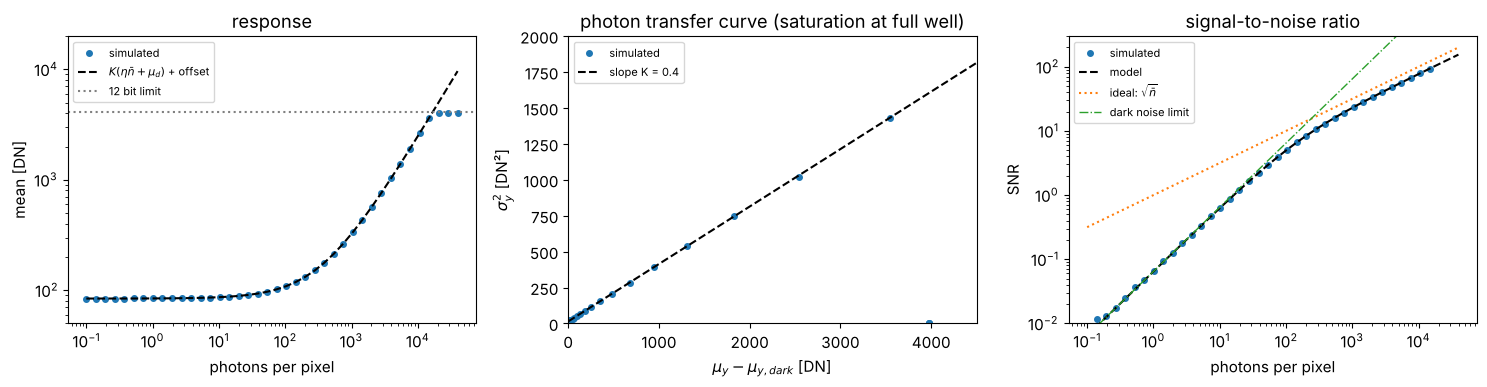

In [7]:
cam = CameraNoiser(quantum_efficiency=0.6, read_noise=6.0, dark_current=500.0, exposure_time=0.1,
                   full_well=1e4, gain=0.4, offset=64.0, bit_depth=12, prnu=0.01, dsnu=1.0, rng=1)
photons = np.logspace(-1, 4.6, 40)
mean, var = [], []
for n in photons:
    a, b = cam(np.full((200, 200, 2), n)).transpose(2, 0, 1)
    mean.append(0.5*(a.mean() + b.mean()))
    var.append(0.5*np.var(a - b))
mean, var = np.array(mean), np.array(var)
snr = (mean - cam.mean_signal(0.0))/np.sqrt(var)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].loglog(photons, mean, "o", ms=4, label="simulated")
axes[0].loglog(photons, cam.mean_signal(photons), "k--", label="$K(\\eta\\bar n + \\mu_d)$ + offset")
axes[0].axhline(2**12 - 1, color="gray", ls=":", label="12 bit limit")
axes[0].set_ylim(50, 2e4); axes[0].set_xlabel("photons per pixel"); axes[0].set_ylabel("mean [DN]")
axes[0].legend(fontsize=8); axes[0].set_title("response")

axes[1].plot(mean - cam.mean_signal(0.0), var, "o", ms=4, label="simulated")
mu = cam.mean_signal(photons) - cam.mean_signal(0.0)
axes[1].plot(mu, cam.temporal_noise(photons)**2, "k--", label=f"slope K = {cam.gain}")
axes[1].set_xlabel("$\\mu_y - \\mu_{y,dark}$ [DN]"); axes[1].set_ylabel("$\\sigma_y^2$ [DN²]")
axes[1].set_xlim(0, 4500); axes[1].set_ylim(0, 2000)
axes[1].legend(fontsize=8); axes[1].set_title("photon transfer curve (saturation at full well)")

eta, sr, md_ = cam.quantum_efficiency, cam.read_noise, cam.dark_current*cam.exposure_time
axes[2].loglog(photons, snr, "o", ms=4, label="simulated")
axes[2].loglog(photons, eta*photons/np.sqrt(eta*photons + md_ + sr**2), "k--", label="model")
axes[2].loglog(photons, np.sqrt(photons), ":", label="ideal: $\\sqrt{\\bar n}$")
axes[2].loglog(photons, eta*photons/np.sqrt(md_ + sr**2), "-.", lw=1, label="dark noise limit")
axes[2].set_ylim(0.01, 300); axes[2].set_xlabel("photons per pixel"); axes[2].set_ylabel("SNR")
axes[2].legend(fontsize=8); axes[2].set_title("signal-to-noise ratio")
fig.tight_layout()

The model functions `CameraNoiser.mean_signal()` and
`CameraNoiser.temporal_noise()` give the expected curves (dashed). Above
$10^4/\eta \approx 1.7\cdot 10^4$ photons the full well clips the signal: the
mean stays constant and the temporal variance drops to zero (the SNR curve
leaves the plot). In the dark, the SNR is limited by read noise and dark
current shot noise.

### Fixed pattern noise and frame averaging

PRNU (pixel-to-pixel gain variation) and DSNU (offset variation) are drawn
once per image shape and then stay fixed for all images processed by the same
`CameraNoiser`, as on a real sensor; `fixed_pattern(shape)` returns them.
Averaging $M$ frames reduces the temporal noise like $1/\sqrt{M}$ but leaves
the fixed pattern untouched, so the noise of the averaged image levels off.

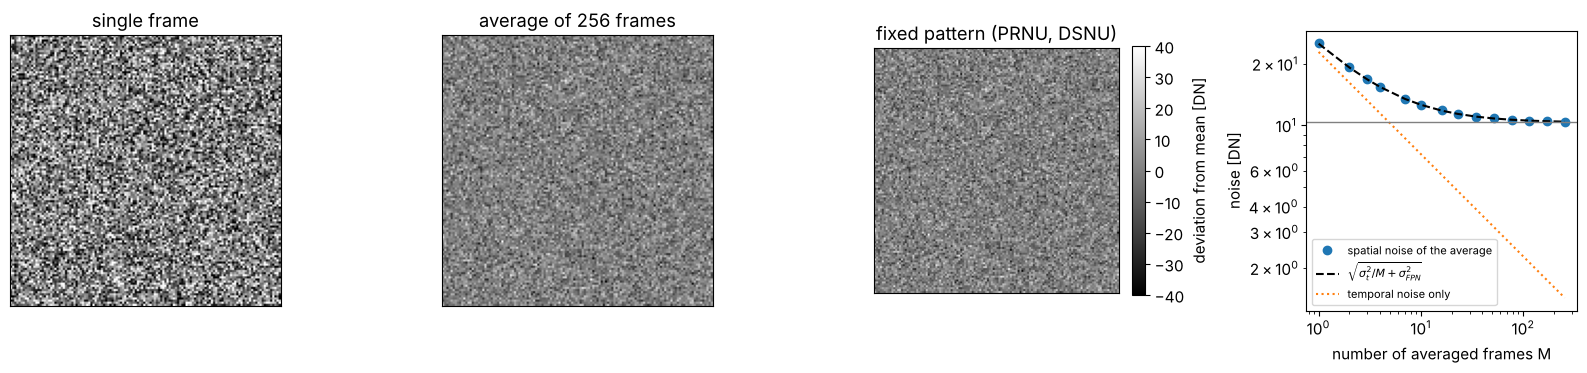

In [8]:
cam_fpn = CameraNoiser(read_noise=5.0, prnu=0.02, dsnu=3.0, gain=1.0, rng=2)
flat = np.full((128, 128, 256), 500.0)     # homogeneous illumination, 500 photons
frames = cam_fpn(flat)
prnu, dsnu = cam_fpn.fixed_pattern((128, 128))

M = np.unique(np.logspace(0, np.log10(256), 15).astype(int))
noise_avg = [np.std(frames[:, :, :m].mean(axis=2)) for m in M]
fpn = np.std(500*(1 + prnu) + dsnu)
temporal = cam_fpn.temporal_noise(500.0)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, img, title in zip(axes[:3], (frames[:, :, 0], frames.mean(axis=2), 500*prnu + dsnu),
                          ("single frame", "average of 256 frames", "fixed pattern (PRNU, DSNU)")):
    im = ax.imshow(img - img.mean(), cmap="gray", vmin=-40, vmax=40)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes[2], fraction=0.046, label="deviation from mean [DN]")
axes[3].loglog(M, noise_avg, "o", label="spatial noise of the average")
axes[3].loglog(M, np.sqrt(temporal**2/M + fpn**2), "k--", label="$\\sqrt{\\sigma_t^2/M + \\sigma_{FPN}^2}$")
axes[3].loglog(M, temporal/np.sqrt(M), ":", label="temporal noise only")
axes[3].axhline(fpn, color="gray", lw=1)
axes[3].set_xlabel("number of averaged frames M"); axes[3].set_ylabel("noise [DN]")
axes[3].legend(fontsize=8)
fig.tight_layout()

### Bit depth and saturation

The ADC rounds to integers and clips to $[0, 2^b - 1]$. With few bits, the
quantization steps become visible in the faint parts of a spot, and an
overexposed spot is cut off flat at the top (the images use a gamma of 0.3
and the cut a logarithmic axis, so that the faint rings are visible). Below, the same defocused PSF
(peak $2\cdot 10^4$ photons, slightly above the full well) seen by a camera
with 4, 8 and 12 bits (the gain is chosen such that the full well fills the
ADC range).

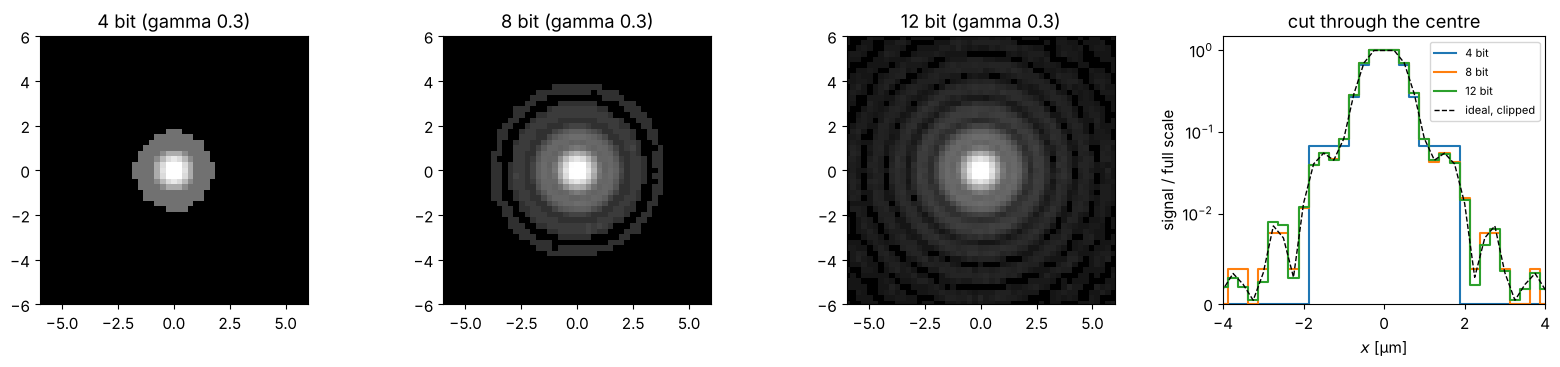

In [9]:
photons = Scaler(2e4)(spot)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, bits in zip(axes[:3], (4, 8, 12)):
    cam_b = CameraNoiser(full_well=1.5e4, gain=(2**bits - 1)/1.5e4, bit_depth=bits, rng=3)
    img = cam_b(photons)
    ax.imshow(img, extent=ext, cmap="gray", norm=PowerNorm(0.3, vmin=0, vmax=2**bits - 1))
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_title(f"{bits} bit (gamma 0.3)")
    axes[3].plot(x, img[N//2]/(2**bits - 1), drawstyle="steps-mid", label=f"{bits} bit")
axes[3].plot(x, np.minimum(photons[N//2], 1.5e4)/1.5e4, "k--", lw=1, label="ideal, clipped")
axes[3].set_xlim(-4, 4); axes[3].set_yscale("symlog", linthresh=0.01); axes[3].set_ylim(0, 1.5)
axes[3].set_xlabel("$x$ [µm]"); axes[3].set_ylabel("signal / full scale")
axes[3].legend(fontsize=8); axes[3].set_title("cut through the centre")
fig.tight_layout()

`utils.add_camera_noise(stack, model, **kwargs)` is a functional shortcut for
`CameraNoiser(model, **kwargs)(stack)`:

In [10]:
noisy = add_camera_noise(Scaler(100.0)(spot), "poisson", rng=0)
print(f"peak counts {noisy.max():.0f}, total counts {noisy.sum():.0f} "
      f"(expected {Scaler(100.0)(spot).sum():.0f})")

peak counts 94, total counts 2556 (expected 2544)


## 3. Centering image stacks with `Centerer`

The intensity centroid (centre of mass)

$$x_c = \frac{\sum x\,I}{\sum I},\qquad y_c = \frac{\sum y\,I}{\sum I}$$

is computed by `utils.center_of_mass(I, x, y, threshold)`. `Centerer(x, y,
x0, y0)` shifts every image so that its centroid lies at $(x_0, y_0)$, by
default the origin. It inherits from `Shifter` and uses the same periodic,
subpixel Fourier shift; fields are centred on the centroid of $\lvert
E\rvert^2$ and stay complex.

### Removing beam jitter

A typical task: a spot that jitters from frame to frame (vibrations, air
turbulence, pointing instability). Averaging the raw frames gives a blurred
spot; centring every frame first gives back the sharp spot. Here 50 frames
of a slightly defocused PSF, randomly displaced by about 1 µm rms (one Airy
radius), with shot noise and some read noise.

rms centroid error: 0.008 µm  (pixel: 0.25 µm)


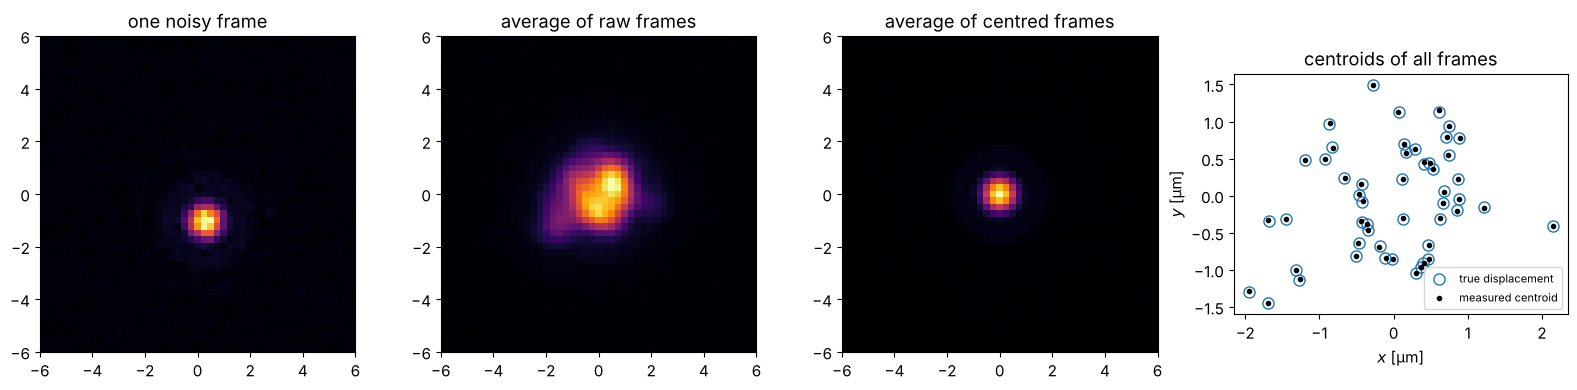

In [11]:
rng = np.random.default_rng(42)
n_frames = 50
jitter = rng.normal(0, 1.0, (n_frames, 2))
field = defocus(h, 4.0)
true_frames = np.dstack([Shifter(jx, jy, x, y)(field) for jx, jy in jitter])
photons = Scaler(500.0, per_image=False)(np.abs(true_frames)**2)
cam_j = CameraNoiser(read_noise=2.0, rng=rng)
frames = cam_j(photons)

centerer = Centerer(x, y, threshold=0.1, iterations=2)
shifts = centerer.get_shifts(frames)
centered = centerer(frames)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
axes[0].imshow(frames[:, :, 0], extent=ext, cmap="inferno")
axes[0].set_title("one noisy frame")
axes[1].imshow(frames.mean(axis=2), extent=ext, cmap="inferno")
axes[1].set_title("average of raw frames")
axes[2].imshow(centered.mean(axis=2), extent=ext, cmap="inferno")
axes[2].set_title("average of centred frames")
for ax in axes[:3]:
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
axes[3].plot(jitter[:, 0], jitter[:, 1], "o", mfc="none", ms=8, label="true displacement")
axes[3].plot(-shifts[:, 0], -shifts[:, 1], "k.", label="measured centroid")
axes[3].set_aspect("equal"); axes[3].set_xlabel("$x$ [µm]"); axes[3].set_ylabel("$y$ [µm]")
axes[3].legend(fontsize=8); axes[3].set_title("centroids of all frames")
fig.tight_layout()

err = -shifts - jitter + np.mean(-shifts - jitter, axis=0)
print(f"rms centroid error: {np.sqrt(np.mean(err**2)):.3f} µm  (pixel: {dx} µm)")

The measured centroids agree with the true displacements to a small fraction
of a pixel. The average of the centred frames is as sharp as a single frame, but much less
noisy.

### Background, threshold and iterations

A constant background $B$ per pixel (dark offset, stray light) pulls the
centroid towards the centre of the image, since it contributes equally
everywhere: with spot power $P$ at $x_s$ and $N^2$ pixels the centroid is
$x_s P/(P + N^2 B)$. Two remedies:

* `threshold` ignores all pixels below `threshold` times the image's peak, which
  removes a background well below the spot's peak completely.
* `iterations` repeats centroiding and shifting. Since the periodic shift moves
  the spot but leaves a constant background unchanged, every pass reduces the
  remaining offset by the factor $N^2B/(P + N^2B)$; this converges, but slowly
  for a strong background.

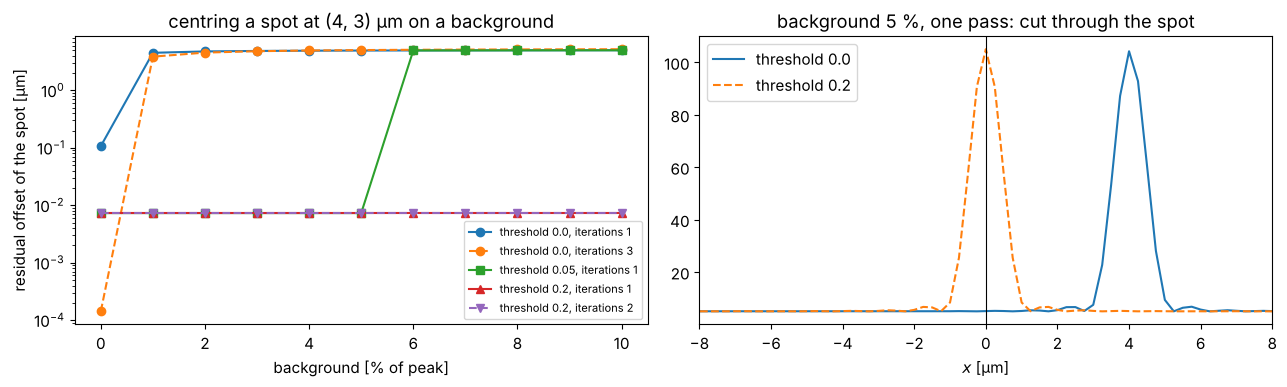

In [12]:
spot_off = Scaler(100.0)(np.abs(Shifter(4.0, 3.0, x, y)(h))**2)   # peak 100, at (4, 3) µm
backgrounds = np.linspace(0, 10, 11)                         # in % of the peak
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for thr, it, m in ((0.0, 1, "o-"), (0.0, 3, "o--"), (0.05, 1, "s-"), (0.2, 1, "^-"), (0.2, 2, "v--")):
    residual = []
    for bg in backgrounds:
        img = spot_off + bg
        c = Centerer(x, y, threshold=thr, iterations=it)(img)
        residual.append(np.hypot(*center_of_mass(c - bg, x, y)))
    axes[0].semilogy(backgrounds, np.maximum(residual, 1e-6), m,
                     label=f"threshold {thr}, iterations {it}")
axes[0].set_xlabel("background [% of peak]"); axes[0].set_ylabel("residual offset of the spot [µm]")
axes[0].legend(fontsize=8); axes[0].set_title("centring a spot at (4, 3) µm on a background")

img = spot_off + 5
for thr, ls in ((0.0, "-"), (0.2, "--")):
    c = Centerer(x, y, threshold=thr)(img)
    row = np.argmax(c.max(axis=1))
    axes[1].plot(x, c[row], ls, label=f"threshold {thr}")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlim(-8, 8); axes[1].set_xlabel("$x$ [µm]")
axes[1].legend(); axes[1].set_title("background 5 %, one pass: cut through the spot")
fig.tight_layout()

A threshold works as long as it lies above the background: 5 % fails as soon
as the background exceeds 5 % of the peak, 20 % works over the whole range.
The remaining offset of a few nm is a discretization effect at the edge of
the thresholded region. Without a threshold, the background here
($128^2 \times 1\,\%$ of the peak) is much stronger than the spot, so the
iterations converge only slowly; they are most useful for a weak residual
background or in combination with a threshold.

### Centroid precision and photon number

With shot noise, the centroid itself is noisy. For a Gaussian spot of rms
width $\sigma$ (per axis) and $N_\text{ph}$ detected photons, the standard
deviation of the centroid is $\sigma/\sqrt{N_\text{ph}}$: localization far
below the diffraction limit is possible with enough photons (the basis of
localization microscopy such as PALM/STORM).

Read noise in the many dark pixels of the frame spoils this: each of the
$128^2$ pixels contributes noise with a lever arm of up to half the image
size. A threshold removes most of these pixels, but only once the spot's peak
is well above the noise; at low photon numbers the maximum of the frame is
itself a noise pixel and the threshold does not help. (In practice one would
additionally restrict the centroid to a region of interest around the spot.)

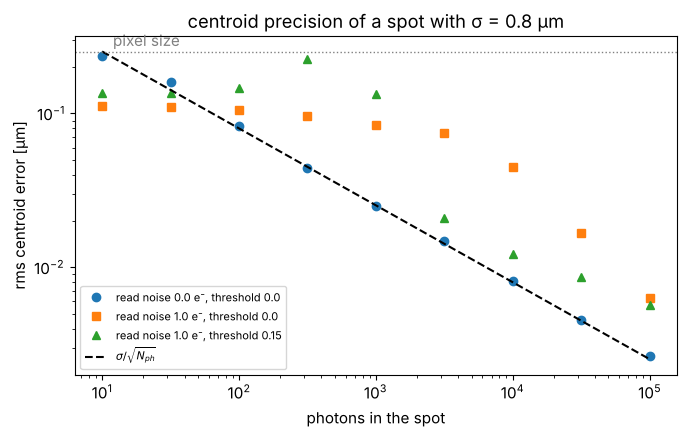

In [13]:
sigma_spot = 0.8
gauss_spot = np.exp(-(X**2 + Y**2)/(2*sigma_spot**2))
n_total = np.logspace(1, 5, 9)
fig, ax = plt.subplots(figsize=(7, 4.5))
for read_noise, thr, m in ((0.0, 0.0, "o"), (1.0, 0.0, "s"), (1.0, 0.15, "^")):
    rms = []
    for n in n_total:
        photons = Scaler(n, measure="total")(gauss_spot)
        stack = CameraNoiser(read_noise=read_noise, rng=5)(np.repeat(photons[:, :, None], 200, axis=2))
        c = np.array([center_of_mass(np.maximum(stack[:, :, i], 0), x, y, threshold=thr)
                      for i in range(200)])
        rms.append(np.std(c[:, 0]))
    ax.loglog(n_total, rms, m, label=f"read noise {read_noise} e⁻, threshold {thr}")
ax.loglog(n_total, sigma_spot/np.sqrt(n_total), "k--", label="$\\sigma/\\sqrt{N_{ph}}$")
ax.axhline(dx, color="gray", ls=":", lw=1); ax.text(12, dx*1.1, "pixel size", color="gray")
ax.set_xlabel("photons in the spot"); ax.set_ylabel("rms centroid error [µm]")
ax.legend(fontsize=8); ax.set_title(f"centroid precision of a spot with σ = {sigma_spot} µm")
fig.tight_layout()

### Individual or common centring: `per_image`

For a through-focus stack the image positions themselves can carry
information, e.g. a spot that walks sideways with defocus because the beam is
tilted. Centring every image individually (`per_image=True`, default) removes
this walk-off. With `per_image=False`, the whole stack is shifted by one
common shift that centres the summed intensity: the stack as a whole is
centred, the relative positions stay intact.

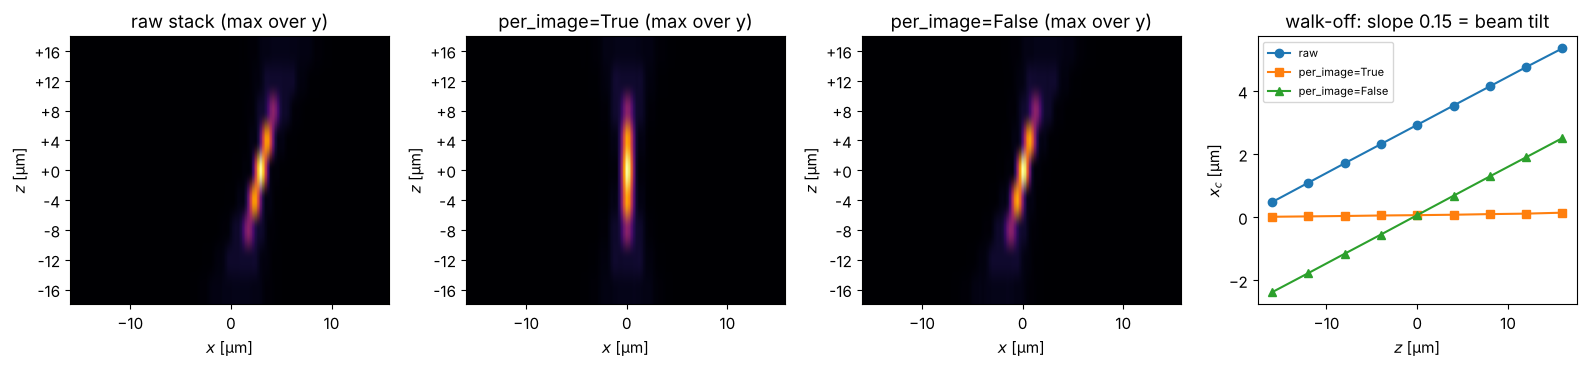

In [14]:
tilt = 0.15                                   # beam tilt in rad: the spot walks by tilt*z
walk = np.dstack([defocus(h*np.exp(1j*k*tilt*X), z) for z in z_stack])
# the tilted beam leaves the axis; start it at x = 3 µm in focus
walk = Shifter(3.0, 1.0, x, y)(walk)
I_walk = np.abs(walk)**2

individual = Centerer(x, y, per_image=True)(walk)
common = Centerer(x, y, per_image=False)(walk)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, stack, title in zip(axes[:3], (walk, individual, common),
                            ("raw stack", "per_image=True", "per_image=False")):
    I_st = np.abs(stack)**2
    ax.imshow(I_st.max(axis=0).T, extent=(x[0], x[-1], 0, len(z_stack)), aspect="auto",
              cmap="inferno", origin="lower")
    ax.set_yticks(np.arange(len(z_stack)) + 0.5, [f"{z:+.0f}" for z in z_stack])
    ax.set_xlabel("$x$ [µm]"); ax.set_ylabel("$z$ [µm]"); ax.set_title(title + " (max over y)")
for stack, label, m in ((walk, "raw", "o-"), (individual, "per_image=True", "s-"),
                        (common, "per_image=False", "^-")):
    xc = [center_of_mass(np.abs(stack[:, :, i])**2, x, y)[0] for i in range(len(z_stack))]
    axes[3].plot(z_stack, xc, m, label=label)
axes[3].set_xlabel("$z$ [µm]"); axes[3].set_ylabel("$x_c$ [µm]"); axes[3].legend(fontsize=8)
axes[3].set_title(f"walk-off: slope {tilt} = beam tilt")
fig.tight_layout()

## 4. A complete pipeline

Putting everything together: a simulated through-focus stack of a beam that
jitters and walks off, converted to photons with one common `Scaler` (peak
2000 photons in the stack), recorded by a 10 bit camera, centred frame by
frame with a threshold, and finally scaled to unit power per image for a
quantitative comparison with the noise-free simulation.

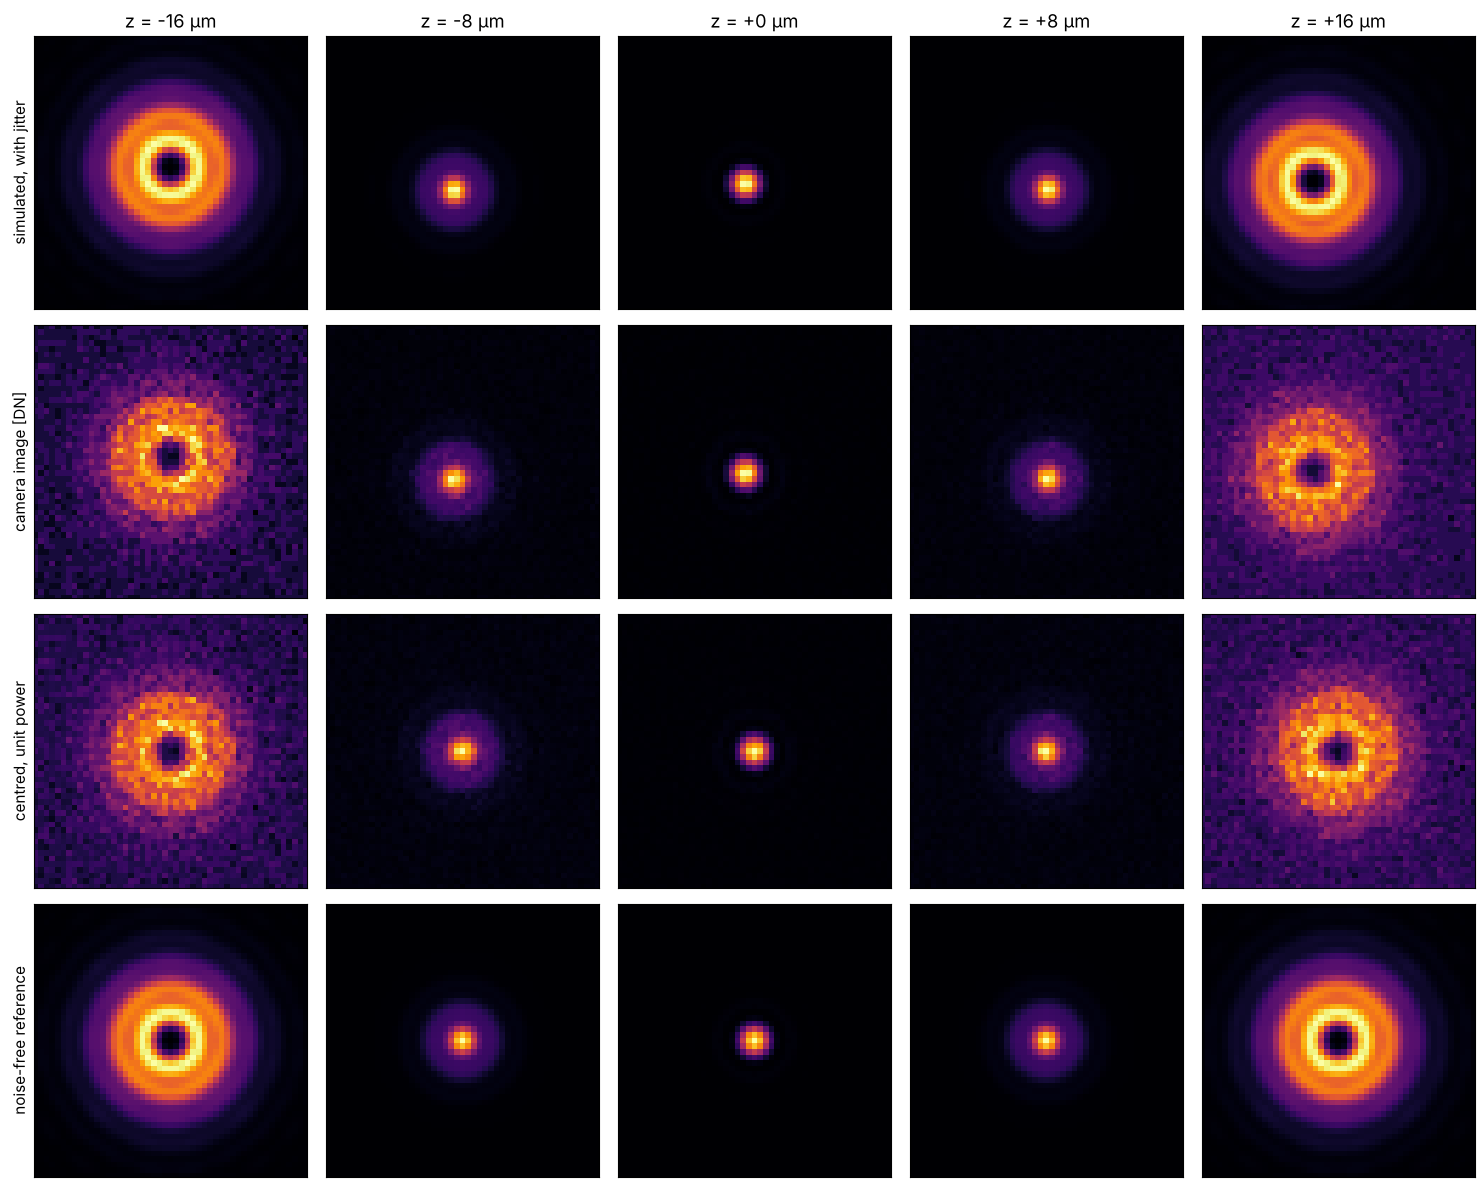

In [15]:
rng = np.random.default_rng(7)
jitter = rng.normal(0, 0.8, (len(z_stack), 2))
truth = np.dstack([defocus(h, z) for z in z_stack])
raw = np.dstack([Shifter(jx, jy, x, y)(truth[:, :, i]) for i, (jx, jy) in enumerate(jitter)])

to_photons = Scaler(2000.0, per_image=False)
camera = CameraNoiser(quantum_efficiency=0.7, read_noise=3.0, gain=1023/5000, offset=10.0,
                      bit_depth=10, full_well=5000, rng=rng)
measured = camera(to_photons(raw))
dark = camera.mean_signal(0.0)
centered = Centerer(x, y, threshold=0.1, iterations=2)(measured - dark)
normalized = Scaler(1.0, measure="total", pixel_area=dA)(centered)
reference = Scaler(1.0, measure="total", pixel_area=dA)(np.abs(truth)**2)

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
show = (0, 2, 4, 6, 8)
rows = ((np.abs(raw)**2, "simulated, with jitter"), (measured, "camera image [DN]"),
        (normalized, "centred, unit power"), (reference, "noise-free reference"))
for r, (stack, title) in enumerate(rows):
    for c, i in enumerate(show):
        ax = axes[r, c]
        ax.imshow(stack[:, :, i], extent=ext, cmap="inferno")
        ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"z = {z_stack[i]:+.0f} µm")
        if c == 0:
            ax.set_ylabel(title)
fig.tight_layout()

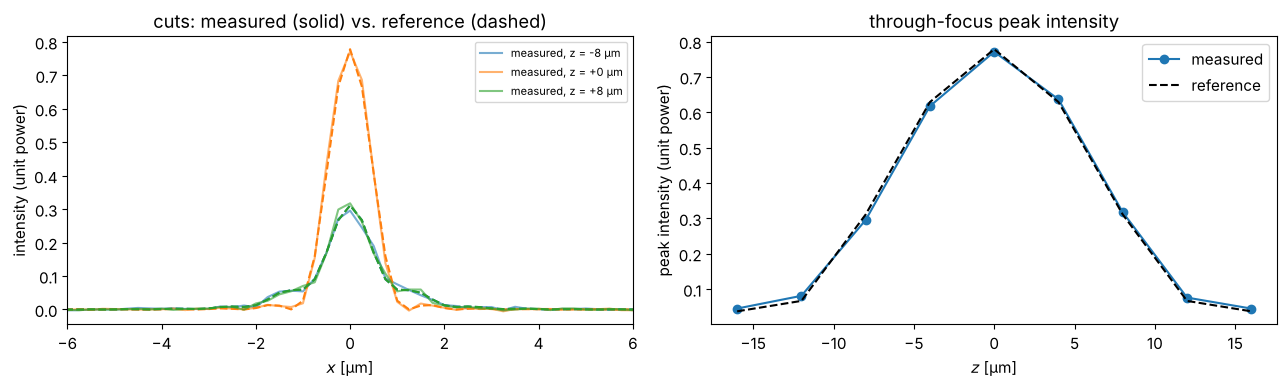

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, color in zip((2, 4, 6), ("C0", "C1", "C2")):
    axes[0].plot(x, normalized[N//2, :, i], color=color, alpha=0.6, label=f"measured, z = {z_stack[i]:+.0f} µm")
    axes[0].plot(x, reference[N//2, :, i], "--", color=color, lw=1.5)
axes[0].set_xlim(-6, 6); axes[0].set_xlabel("$x$ [µm]"); axes[0].set_ylabel("intensity (unit power)")
axes[0].legend(fontsize=8); axes[0].set_title("cuts: measured (solid) vs. reference (dashed)")

axes[1].plot(z_stack, normalized.max(axis=(0, 1)), "o-", label="measured")
axes[1].plot(z_stack, reference.max(axis=(0, 1)), "k--", label="reference")
axes[1].set_xlabel("$z$ [µm]"); axes[1].set_ylabel("peak intensity (unit power)")
axes[1].legend(); axes[1].set_title("through-focus peak intensity")
fig.tight_layout()

After subtracting the dark level, centring and normalizing to unit power, the
measured stack agrees with the noise-free simulation up to the shot and read
noise: the through-focus curve of the peak intensity, a typical quantity for
focus finding, is recovered.

**Summary**

* `Scaler` sets the peak, mean or total of the field strength or the intensity,
  for fields and intensities alike; `per_image=False` keeps relative
  intensities in a stack.
* `CameraNoiser` provides Gaussian noise, Poisson shot noise, and the EMVA
  1288 linear camera model with quantum efficiency, dark current, read noise,
  full well, gain, offset, ADC bit depth and fixed pattern noise; its
  `mean_signal()` and `temporal_noise()` give the expected curves.
* `Centerer` shifts images onto their intensity centroid with subpixel
  precision, individually or with a common shift for the whole stack; a
  threshold and a second iteration make it robust against background.